# РОЗДІЛ 3. ОБЕРНЕНА ЗАДАЧА ТА МЕТОДИКА ЇЇ РОЗВ’ЯЗАННЯ НА ОСНОВІ МЕТОДУ ГОЛОВНИХ КОМПОНЕНТІВ (PCA) ТА МАШИННОГО НАВЧАННЯ

У цьому розділі реалізовано математичну постановку та обчислювальну методику розв’язання **оберненої коефіцієнтної задачі** ідентифікації вектора невідомих фізичних параметрів струни $\boldsymbol{\theta} = [a, l, A]^T \in \mathbb{R}^3$:
- **Підрозділ 3.1.** Математична постановка оберненої задачі, вибір гарантованої підобласті спостереження $\Omega_s = [0{,}10;\; 0{,}70]\text{ м} \times [0{,}01;\; 0{,}05]\text{ с}$ та сітки датчиків $N_x = 7,\; N_t = 7$ ($P = 49$ точок) за наявності мультиплікативного шуму $\delta = 1{,}0\%$ (**Рисунок 3.1**).
- **Підрозділ 3.2.** Метод головних компонентів (PCA) для ортогонального проєктування $\mathbb{R}^{49} \to \mathbb{R}^4$ та фільтрації високочастотних завад (**Рисунок 3.2**).
- **Підрозділ 3.3.** Генерація синтетичної навчальної вибірки методом латинського гіперкуба (LHS) обсягом $M = 100\,000$ реалізацій ($80\,000$ навчальних / $20\,000$ тестових).
- **Підрозділ 3.4.** Архітектура регресійних моделей машинного навчання на латентному PCA-просторі (`MLP`, `Extra Trees`, `k-NN`, `Cascade MLP`).
- **Підрозділ 3.5.** Метрики якості ідентифікації (`MAE`, `RMSE`, `MAPE`, $R^2$).

## 3.1. Математична постановка оберненої задачі та схема розміщення датчиків (**Рисунок 3.1**)

Вектор невідомих параметрів належить тривимірному гіперпаралелепіпеду допустимих значень:
$$\boldsymbol{\theta} = [a,\; l,\; A]^T \in \Theta = [1{,}0;\; 3{,}2]\text{ м/с} \times [0{,}8;\; 1{,}2]\text{ м} \times [0{,}8;\; 1{,}2]\text{ м}^{-1}.$$

Усі $N_x = 7$ безконтактних оптичних датчиків розташовуються у гарантованій спільній області $x_i \in [0{,}10;\; 0{,}70]\text{ м} < l_{\min} = 0{,}80\text{ м}$, а реєстрація ведеться у $N_t = 7$ моментів часу $t_j \in [0{,}01;\; 0{,}05]$ с, що утворює вектор спостережень розмірності $P = 7 \times 7 = 49$:
$$\tilde{U}_p = U(x_i, t_j; \boldsymbol{\theta}) \cdot (1 + \delta \cdot \xi_p), \quad \xi_p \sim \mathcal{N}(0, 1), \quad \delta = 0{,}01.$$

Підрозділ 3.1. Параметри оператора спостереження та сітки датчиків:
  Просторовий інтервал датчиків : x in [0.10; 0.70] м (N_x = 7)
  Координати датчиків x_i       : [0.1 0.2 0.3 0.4 0.5 0.6 0.7] м
  Часовий інтервал реєстрації   : t in [0.01; 0.05] с (N_t = 7)
  Моменти вимірювань t_j        : [10.   16.67 23.33 30.   36.67 43.33 50.  ] мс
  Загальна кількість відліків   : P = N_x * N_t = 49
  Рівень мультиплікативного шуму: delta = 1.0%


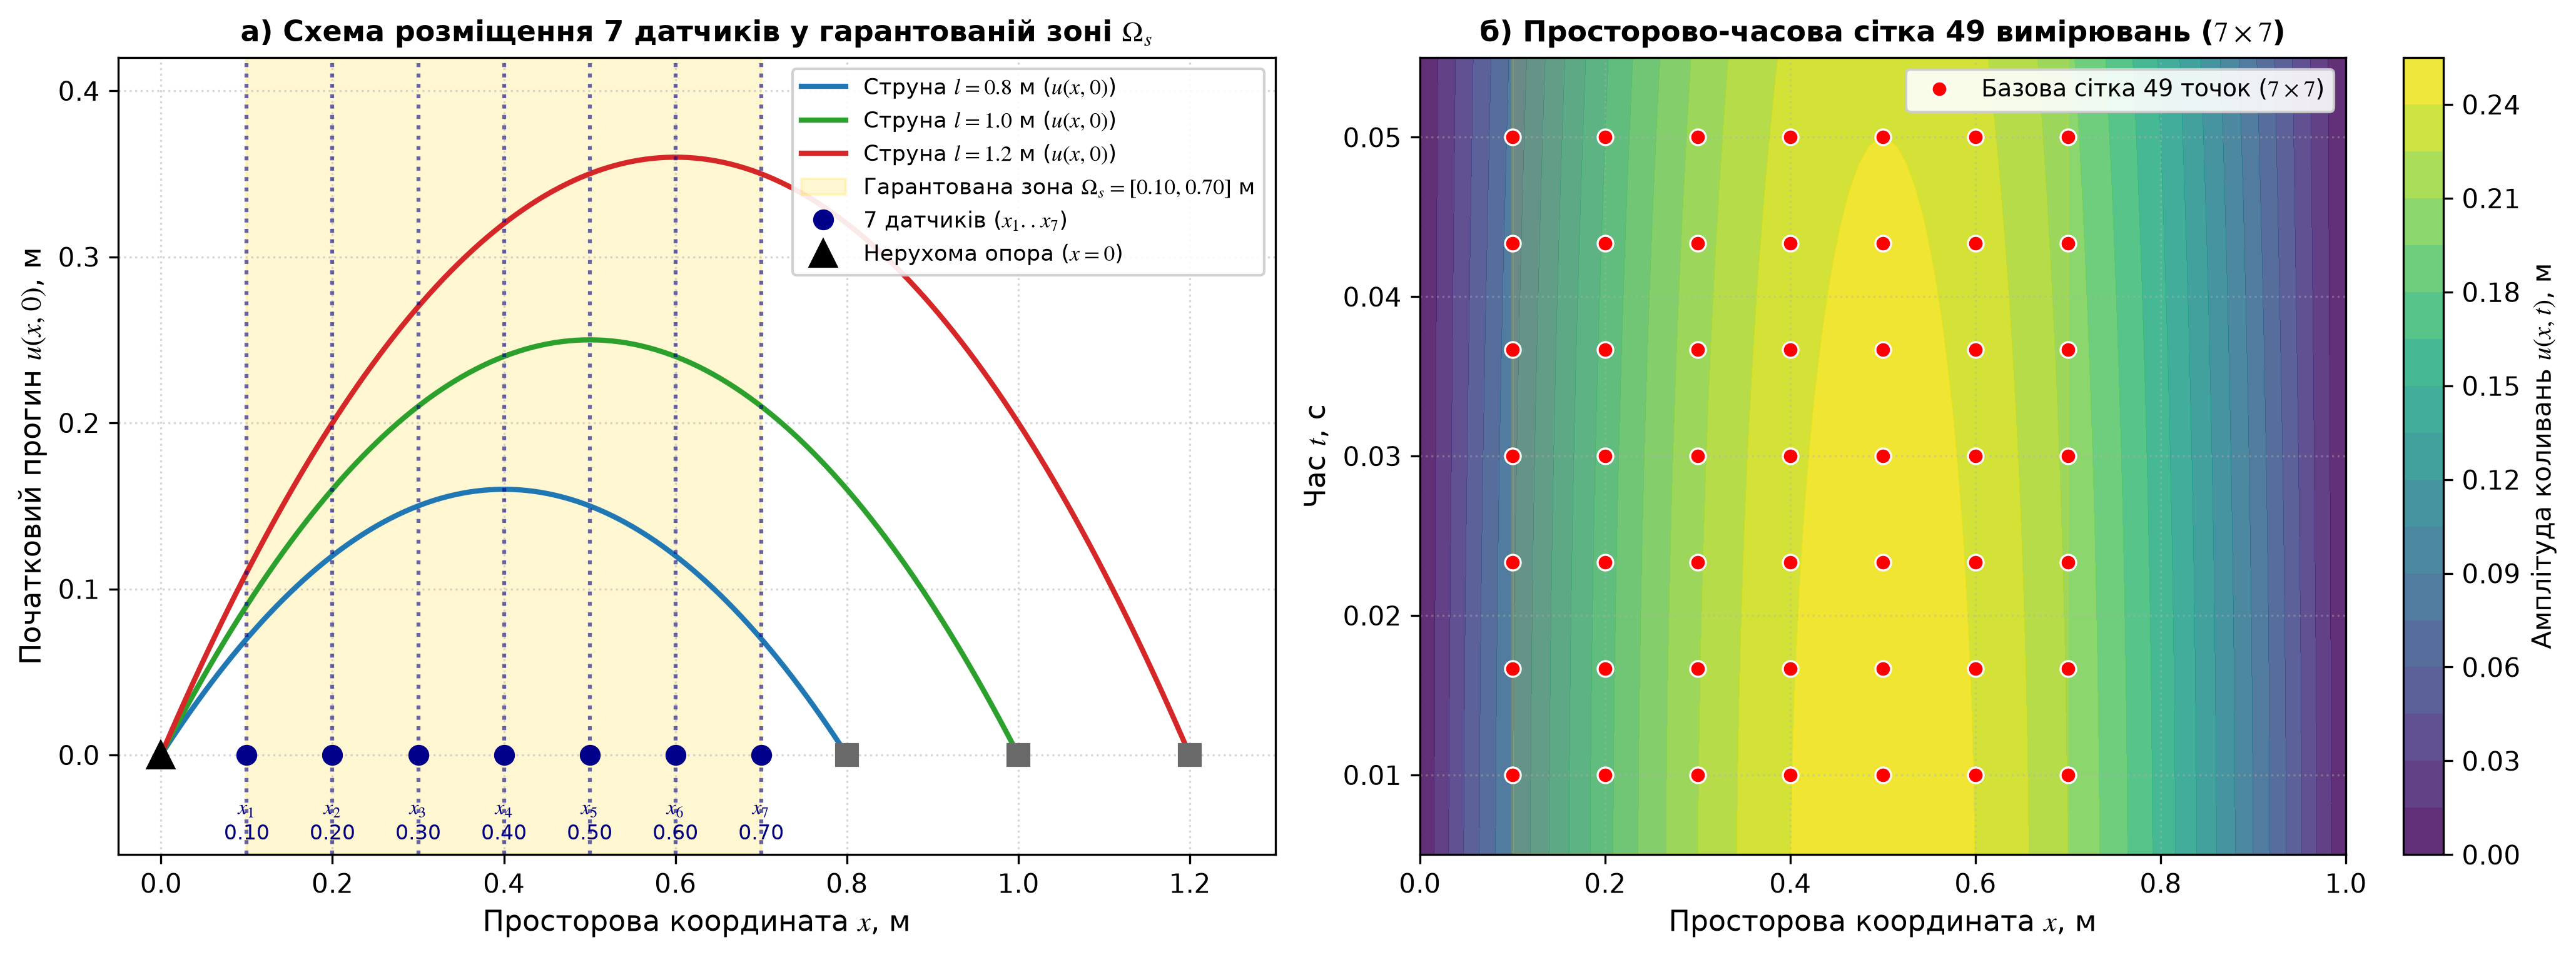

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BOUNDS = np.array([
    [1.0, 3.2],   # Фазова швидкість a, м/с
    [0.8, 1.2],   # Робоча довжина струни l, м
    [0.8, 1.2],   # Параметр початкової кривини A, м^-1
], dtype=np.float64)

X_MIN, X_MAX = 0.10, 0.70
T_MIN, T_MAX = 0.01, 0.05
N_X_BASE, N_T_BASE = 7, 7
NOISE_DELTA_BASE = 0.01
K_HARMONICS = 41

XS_BASE = np.linspace(X_MIN, X_MAX, N_X_BASE)
TS_BASE = np.linspace(T_MIN, T_MAX, N_T_BASE)
XG_BASE, TG_BASE = np.meshgrid(XS_BASE, TS_BASE)
X_FLAT_BASE, T_FLAT_BASE = XG_BASE.ravel(), TG_BASE.ravel()

def eval_forward_operator_batch(a, l, A, x_pts, t_pts, K=41):
    xf = x_pts[None, :]
    tf = t_pts[None, :]
    U = np.zeros((a.shape[0], x_pts.shape[0]), dtype=np.float64)
    for k in range(1, K + 1):
        m = 2.0 * k - 1.0
        coeff = (8.0 * A * (l ** 2)) / ((np.pi ** 3) * (m ** 3))
        U += coeff * np.sin(m * np.pi * xf / l) * np.cos(m * np.pi * a * tf / l)
    return U

print("=" * 85)
print("Підрозділ 3.1. Параметри оператора спостереження та сітки датчиків:")
print(f"  Просторовий інтервал датчиків : x in [{X_MIN:.2f}; {X_MAX:.2f}] м (N_x = {N_X_BASE})")
print(f"  Координати датчиків x_i       : {np.round(XS_BASE, 3)} м")
print(f"  Часовий інтервал реєстрації   : t in [{T_MIN:.2f}; {T_MAX:.2f}] с (N_t = {N_T_BASE})")
print(f"  Моменти вимірювань t_j        : {np.round(TS_BASE * 1000, 2)} мс")
print(f"  Загальна кількість відліків   : P = N_x * N_t = {N_X_BASE * N_T_BASE}")
print(f"  Рівень мультиплікативного шуму: delta = {NOISE_DELTA_BASE * 100:.1f}%")
print("=" * 85)

# Рисунок 3.1: Схема просторового розміщення 7 датчиків та сітка 49 точок спостереження
fig3_1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=150)
x_dense = np.linspace(0, 1.25, 300)
for l_val, col_l in zip([0.8, 1.0, 1.2], ["#1f77b4", "#2ca02c", "#d62728"]):
    mask = x_dense <= l_val
    ax1.plot(x_dense[mask], 1.0 * x_dense[mask] * (l_val - x_dense[mask]), lw=2.0, color=col_l, label=f"Струна $l = {l_val}$ м ($u(x,0)$)")
ax1.axvspan(X_MIN, X_MAX, alpha=0.18, color="gold", label=r"Гарантована зона $\Omega_s = [0.10, 0.70]$ м")
for i_s, x_s in enumerate(XS_BASE):
    ax1.axvline(x_s, color="darkblue", linestyle=":", alpha=0.6)
    ax1.plot(x_s, 0.0, "o", color="darkblue", markersize=7, label="7 датчиків ($x_1..x_7$)" if i_s == 0 else "")
ax1.set_title(r"а) Схема розміщення 7 датчиків у гарантованій зоні $\Omega_s$", fontsize=11, fontweight="bold")
ax1.set_xlabel("Просторова координата $x$, м", fontsize=11)
ax1.set_ylabel("Початковий прогин $u(x, 0)$, м", fontsize=11)
ax1.set_ylim(-0.06, 0.42)
ax1.set_xlim(-0.05, 1.30)
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.legend(loc="upper right", fontsize=8.5)

t_grid_dense = np.linspace(0.005, 0.055, 100)
x_grid_dense = np.linspace(0.0, 1.0, 100)
X_m, T_m = np.meshgrid(x_grid_dense, t_grid_dense)
U_demo = eval_forward_operator_batch(np.array([[2.0]]), np.array([[1.0]]), np.array([[1.0]]), X_m.ravel(), T_m.ravel(), K=31).reshape(X_m.shape)
cs = ax2.contourf(X_m, T_m, U_demo, levels=20, cmap="viridis", alpha=0.85)
plt.colorbar(cs, ax=ax2).set_label("Амплітуда коливань $u(x, t)$, м", fontsize=10)
ax2.plot(X_FLAT_BASE, T_FLAT_BASE, "ro", markersize=6, markeredgecolor="white", label=r"Базова сітка 49 точок ($7 \times 7$)")
ax2.set_title(r"б) Просторово-часова сітка 49 вимірювань ($7 \times 7$)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Просторова координата $x$, м", fontsize=11)
ax2.set_ylabel("Час $t$, с", fontsize=11)
ax2.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

## 3.2–3.3. Генерація навчальної вибірки методом латинського гіперкуба (LHS) та метод головних компонентів (PCA) (**Рисунок 3.2**)

Стратифіковане семплювання за схемою латинського гіперкуба (формула (3.11)) забезпечує рівномірне покриття простору параметрів $\Theta$:
$$\theta_{m,j} = \theta_j^{\min} + \frac{\pi_j(m) - 1 + \xi_{m,j}}{M} \left(\theta_j^{\max} - \theta_j^{\min}\right), \quad m = \overline{1, M}, \quad j \in \{1, 2, 3\}.$$

Спектральний розклад вибіркової коваріаційної матриці $\boldsymbol{\Sigma} = \frac{1}{M_{\mathrm{train}}-1} \dot{\mathbf{X}}^T \dot{\mathbf{X}} \in \mathbb{R}^{49 \times 49}$ визначає ортогональну матрицю навантажень $\mathbf{W}_K = [\mathbf{w}_1, \dots, \mathbf{w}_K] \in \mathbb{R}^{49 \times K}$ та латентні координати $\mathbf{z} = \mathbf{W}_K^T (\tilde{\mathbf{u}} - \boldsymbol{\mu}) \in \mathbb{R}^K$.

Підрозділи 3.2–3.3. Статистика LHS-семплювання та PCA-декомпозиції (R^49 -> R^4):
  ГК 1: lambda_1 = 1.5809e-01 | частка дисперсії = 98.369% | кумулятивна = 98.369%
  ГК 2: lambda_2 = 2.1524e-03 | частка дисперсії = 1.339% | кумулятивна = 99.708%
  ГК 3: lambda_3 = 2.6591e-04 | частка дисперсії = 0.165% | кумулятивна = 99.874%
  ГК 4: lambda_4 = 6.8901e-06 | частка дисперсії = 0.004% | кумулятивна = 99.878%


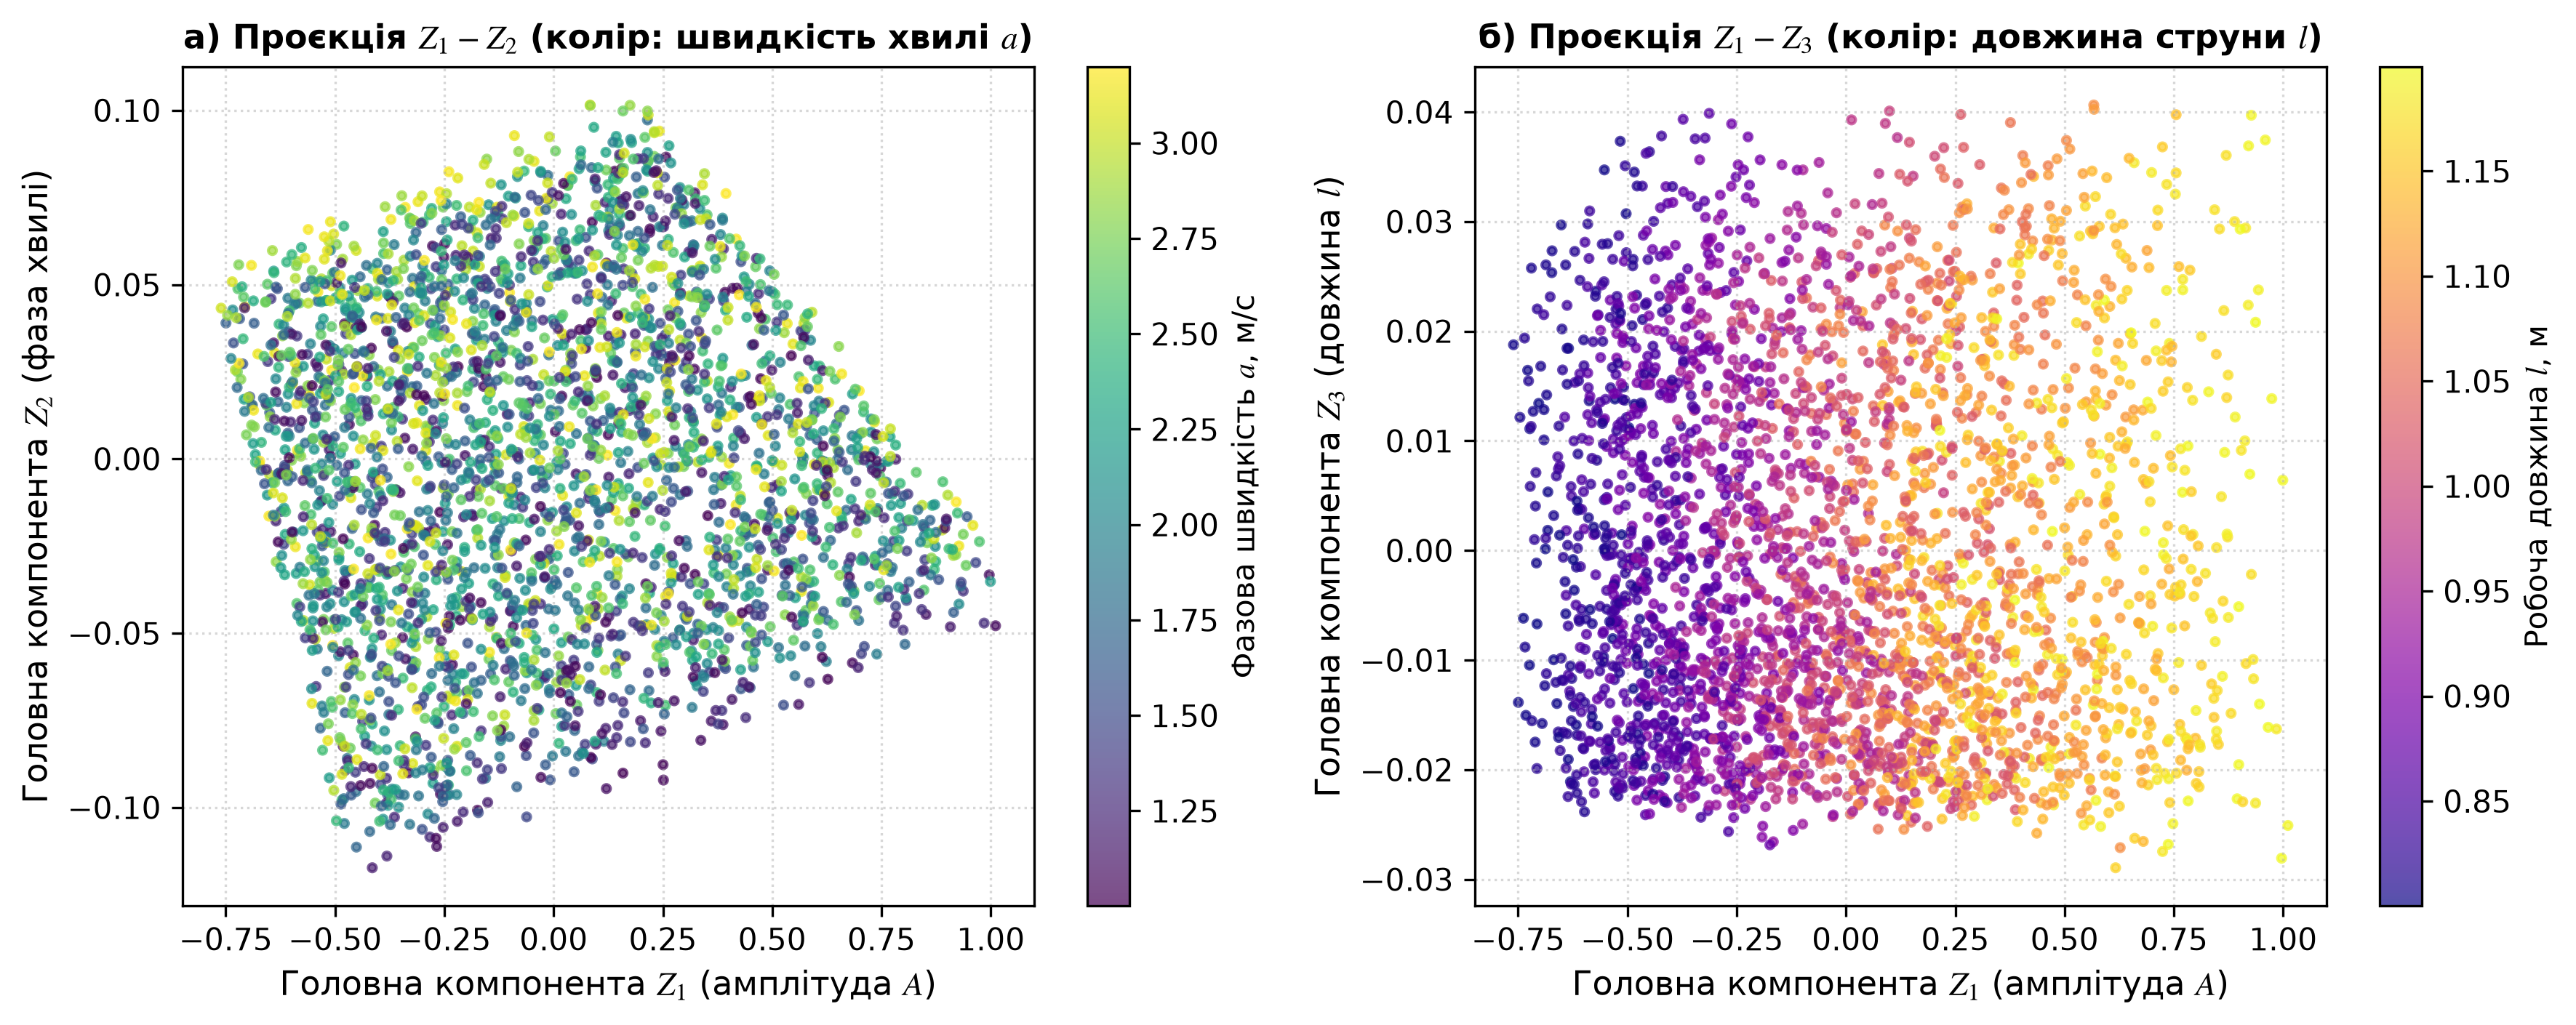

In [2]:
def lhs_sample(n_samples, bounds, seed=42):
    rng = np.random.default_rng(seed)
    dim = bounds.shape[0]
    result = np.zeros((n_samples, dim), dtype=np.float64)
    for j in range(dim):
        perm = rng.permutation(n_samples)
        u = rng.uniform(0.0, 1.0, size=n_samples)
        strat = (perm + u) / float(n_samples)
        result[:, j] = bounds[j, 0] + strat * (bounds[j, 1] - bounds[j, 0])
    return result

# Генерація вибірки методом LHS та PCA-розклад
Y_sample = lhs_sample(20000, BOUNDS, seed=42)
U_clean = eval_forward_operator_batch(Y_sample[:, 0:1], Y_sample[:, 1:2], Y_sample[:, 2:3], X_FLAT_BASE, T_FLAT_BASE, K=K_HARMONICS)
U_noisy = U_clean + np.random.default_rng(42).normal(0.0, NOISE_DELTA_BASE * np.abs(U_clean))

mu_pca = np.mean(U_noisy, axis=0)
cov_mat = np.cov(U_noisy - mu_pca, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov_mat)
idx_sort = np.argsort(eigvals)[::-1]
eigvals = np.maximum(eigvals[idx_sort], 0.0)
eigvecs = eigvecs[:, idx_sort]
Z_latent = (U_noisy - mu_pca) @ eigvecs[:, :4]
expl_ratio = eigvals / np.sum(eigvals) * 100.0
cum_expl = np.cumsum(expl_ratio)

print("=" * 85)
print("Підрозділи 3.2–3.3. Статистика LHS-семплювання та PCA-декомпозиції (R^49 -> R^4):")
for k_i in range(4):
    print(f"  ГК {k_i+1}: lambda_{k_i+1} = {eigvals[k_i]:.4e} | частка дисперсії = {expl_ratio[k_i]:.3f}% | кумулятивна = {cum_expl[k_i]:.3f}%")
print("=" * 85)

# Рисунок 3.2: Проєкції латентного простору Z1-Z2 та Z1-Z3
sub_idx = np.random.default_rng(42).choice(len(Z_latent), 3000, replace=False)
fig3_2, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.0, 4.8), dpi=150)
sc1 = ax1.scatter(Z_latent[sub_idx, 0], Z_latent[sub_idx, 1], c=Y_sample[sub_idx, 0], cmap="viridis", s=7, alpha=0.7)
ax1.set_xlabel(r"Головна компонента $Z_1$ (амплітуда $A$)")
ax1.set_ylabel(r"Головна компонента $Z_2$ (фаза хвилі)")
ax1.set_title(r"а) Проєкція $Z_1 - Z_2$ (колір: швидкість хвилі $a$)", fontweight="bold")
plt.colorbar(sc1, ax=ax1).set_label("Фазова швидкість $a$, м/с")
ax1.grid(True, linestyle=":", alpha=0.5)

sc2 = ax2.scatter(Z_latent[sub_idx, 0], Z_latent[sub_idx, 2], c=Y_sample[sub_idx, 1], cmap="plasma", s=7, alpha=0.7)
ax2.set_xlabel(r"Головна компонента $Z_1$ (амплітуда $A$)")
ax2.set_ylabel(r"Головна компонента $Z_3$ (довжина $l$)")
ax2.set_title(r"б) Проєкція $Z_1 - Z_3$ (колір: довжина струни $l$)", fontweight="bold")
plt.colorbar(sc2, ax=ax2).set_label("Робоча довжина $l$, м")
ax2.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

## 3.4–3.5. Архітектура регресійних моделей машинного навчання та метрики якості ідентифікації

In [3]:
df_arch = pd.DataFrame([
    {"Модель": "1. MLP (Багатошаровий перцептрон)", "Відображення": "R^4 -> R^3", "Конфігурація": "Приховані шари (128, 64, 32), ReLU, Adam, L2 alpha=1e-4"},
    {"Модель": "2. Extra Trees (Екстремальні дерева)", "Відображення": "R^4 -> R^3", "Конфігурація": "Ансамбль B = 300 дерев, випадкові пороги розщеплення MSE"},
    {"Модель": "3. k-NN (Метод k-найближчих сусідів)", "Відображення": "R^4 -> R^3", "Конфігурація": "k = 7 сусідів, ваги оберненої евклідової відстані w_j = 1/d_j"},
    {"Модель": "4. Cascade MLP (Двоетапна схема)", "Відображення": "Етап 1: R^4->[l,A]; Етап 2: R^6->a", "Конфігурація": "Каскадне уточнення фазової швидкості a на основі оцінок (l_hat, A_hat)"},
])
print("=" * 105)
print("Підрозділи 3.4–3.5. Зведена конфігурація досліджуваних моделей машинного навчання:")
print("=" * 105)
print(df_arch.to_string(index=False))
print("=" * 105)

Підрозділи 3.4–3.5. Зведена конфігурація досліджуваних моделей машинного навчання:
                              Модель                       Відображення                                                           Конфігурація
   1. MLP (Багатошаровий перцептрон)                         R^4 -> R^3                Приховані шари (128, 64, 32), ReLU, Adam, L2 alpha=1e-4
2. Extra Trees (Екстремальні дерева)                         R^4 -> R^3               Ансамбль B = 300 дерев, випадкові пороги розщеплення MSE
3. k-NN (Метод k-найближчих сусідів)                         R^4 -> R^3          k = 7 сусідів, ваги оберненої евклідової відстані w_j = 1/d_j
    4. Cascade MLP (Двоетапна схема) Етап 1: R^4->[l,A]; Етап 2: R^6->a Каскадне уточнення фазової швидкості a на основі оцінок (l_hat, A_hat)
